<a href="https://colab.research.google.com/github/moushe-21/EDA-Dataset_Prep-Stat/blob/main/EDA%2CDataPrep%2CStat_CapA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()
df = pd.read_csv('extended_stress_detection_data.csv')

Saving extended_stress_detection_data.csv to extended_stress_detection_data.csv


In [ ]:
# 1.
print("--- 1. Dataset Shape & Columns ---")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("Columns:", df.columns.tolist())


--- 1. Dataset Shape & Columns ---
Shape: 3000 rows, 22 columns
Columns: ['Age', 'Gender', 'Occupation', 'Marital_Status', 'Sleep_Duration', 'Sleep_Quality', 'Wake_Up_Time', 'Bed_Time', 'Physical_Activity', 'Screen_Time', 'Caffeine_Intake', 'Alcohol_Intake', 'Smoking_Habit', 'Work_Hours', 'Travel_Time', 'Social_Interactions', 'Meditation_Practice', 'Exercise_Type', 'Blood_Pressure', 'Cholesterol_Level', 'Blood_Sugar_Level', 'Stress_Detection']


In [ ]:
import numpy as np

# 2.
print("\n--- 2. Data Types & Feature Classification ---")
print(df.dtypes)

num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
target_col = 'Stress_Detection'
if target_col in cat_cols:
    cat_cols.remove(target_col)

print(f"\nNumerical Features ({len(num_cols)}): {num_cols}")
print(f"Categorical Features ({len(cat_cols)}): {cat_cols}")
print(f"Target Feature: {target_col}")


--- 2. Data Types & Feature Classification ---
Age                    float64
Gender                  object
Occupation              object
Marital_Status          object
Sleep_Duration         float64
Sleep_Quality          float64
Wake_Up_Time            object
Bed_Time                object
Physical_Activity      float64
Screen_Time            float64
Caffeine_Intake          int64
Alcohol_Intake           int64
Smoking_Habit           object
Work_Hours             float64
Travel_Time            float64
Social_Interactions    float64
Meditation_Practice     object
Exercise_Type           object
Blood_Pressure         float64
Cholesterol_Level      float64
Blood_Sugar_Level      float64
Stress_Detection        object
dtype: object

Numerical Features (13): ['Age', 'Sleep_Duration', 'Sleep_Quality', 'Physical_Activity', 'Screen_Time', 'Caffeine_Intake', 'Alcohol_Intake', 'Work_Hours', 'Travel_Time', 'Social_Interactions', 'Blood_Pressure', 'Cholesterol_Level', 'Blood_Sugar_Level']
Ca

In [ ]:
# 3.
print("\n--- 3. Missing-Value Analysis ---")
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing, 'Missing_Percentage (%)': missing_pct})
print(missing_df[missing_df['Missing_Count'] > 0] if missing.sum() > 0 else "No missing values found.")


--- 3. Missing-Value Analysis ---
No missing values found.


In [ ]:
# 4.
print("\n--- 4. Duplicate Record Analysis ---")
duplicates = df.duplicated().sum()
print(f"Total duplicate rows: {duplicates}")


--- 4. Duplicate Record Analysis ---
Total duplicate rows: 0


In [ ]:
# 5.
print("\n--- 5. Unrealistic / Out-of-Bound Value Check ---")
unrealistic_checks = {
    'Age': df[(df['Age'] <= 0) | (df['Age'] > 120)].shape[0],
    'Sleep_Duration': df[(df['Sleep_Duration'] < 0) | (df['Sleep_Duration'] > 24)].shape[0],
    'Work_Hours': df[(df['Work_Hours'] < 0) | (df['Work_Hours'] > 24)].shape[0],
    'Screen_Time': df[(df['Screen_Time'] < 0) | (df['Screen_Time'] > 24)].shape[0]
}
print("Unrealistic value counts:", unrealistic_checks)


--- 5. Unrealistic / Out-of-Bound Value Check ---
Unrealistic value counts: {'Age': 0, 'Sleep_Duration': 0, 'Work_Hours': 0, 'Screen_Time': 1}


In [ ]:
# 6.
print("--- 6. Numerical Features Summary Statistics ---")
print(df[num_cols].describe().T)

--- 6. Numerical Features Summary Statistics ---
                      count        mean        std     min       25%      50%  \
Age                  3000.0   38.846530   7.586693   16.98   33.0975   38.735   
Sleep_Duration       3000.0    6.317590   1.137913    1.92    5.7000    6.300   
Sleep_Quality        3000.0    3.871413   0.989186    0.52    3.2200    3.900   
Physical_Activity    3000.0    2.959787   1.180590   -1.34    2.0975    3.000   
Screen_Time          3000.0    4.064293   1.167995   -0.44    3.2100    4.000   
Caffeine_Intake      3000.0    1.807667   0.825168    0.00    1.0000    2.000   
Alcohol_Intake       3000.0    0.875333   0.663278    0.00    0.0000    1.000   
Work_Hours           3000.0    8.249623   1.354493    3.28    7.3100    8.050   
Travel_Time          3000.0    2.836517   1.371720   -1.67    1.9600    2.970   
Social_Interactions  3000.0    3.175870   1.224617   -0.82    2.2600    3.040   
Blood_Pressure       3000.0  138.011590  13.160897  109.13  

In [ ]:
# 7.
print("\n--- 7. Categorical Unique Values & Frequencies ---")
for col in cat_cols:
    print(f"\nFrequency table for '{col}':")
    print(df[col].value_counts().head(10))


--- 7. Categorical Unique Values & Frequencies ---

Frequency table for 'Gender':
Gender
Female    1521
Male      1479
Name: count, dtype: int64

Frequency table for 'Occupation':
Occupation
Teacher               140
Chef                  108
Nurse                  86
Photographer           86
Architect              74
Scientist              68
Electrician            66
Graphic Designer       62
Software Engineer      62
Software Developer     61
Name: count, dtype: int64

Frequency table for 'Marital_Status':
Marital_Status
Single      1372
Married     1364
Divorced     264
Name: count, dtype: int64

Frequency table for 'Wake_Up_Time':
Wake_Up_Time
7:00 AM    726
8:00 AM    487
6:00 AM    473
6:30 AM    465
7:30 AM    286
5:30 AM    260
9:00 AM    185
5:00 AM     76
8:30 AM     28
4:30 AM     14
Name: count, dtype: int64

Frequency table for 'Bed_Time':
Bed_Time
6:00 PM     571
11:00 PM    482
10:30 PM    478
5:00 PM     382
10:00 PM    323
7:00 PM     133
11:30 PM    130
9:30 PM    

In [ ]:
# 8.
print("\n--- 8. Target-class Distribution ---")
counts = df[target_col].value_counts()
pcts = df[target_col].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': counts, 'Percentage (%)': pcts}))


--- 8. Target-class Distribution ---
                  Count  Percentage (%)
Stress_Detection                       
Medium             1258       41.933333
High               1118       37.266667
Low                 624       20.800000


In [ ]:
# 9.
ratio = counts.max() / counts.min()
print(f"\n--- 9. Class-imbalance Analysis ---")
print(f"Majority-to-Minority Ratio: {ratio:.2f}:1")


--- 9. Class-imbalance Analysis ---
Majority-to-Minority Ratio: 2.02:1


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

<Figure size 1400x1000 with 0 Axes>

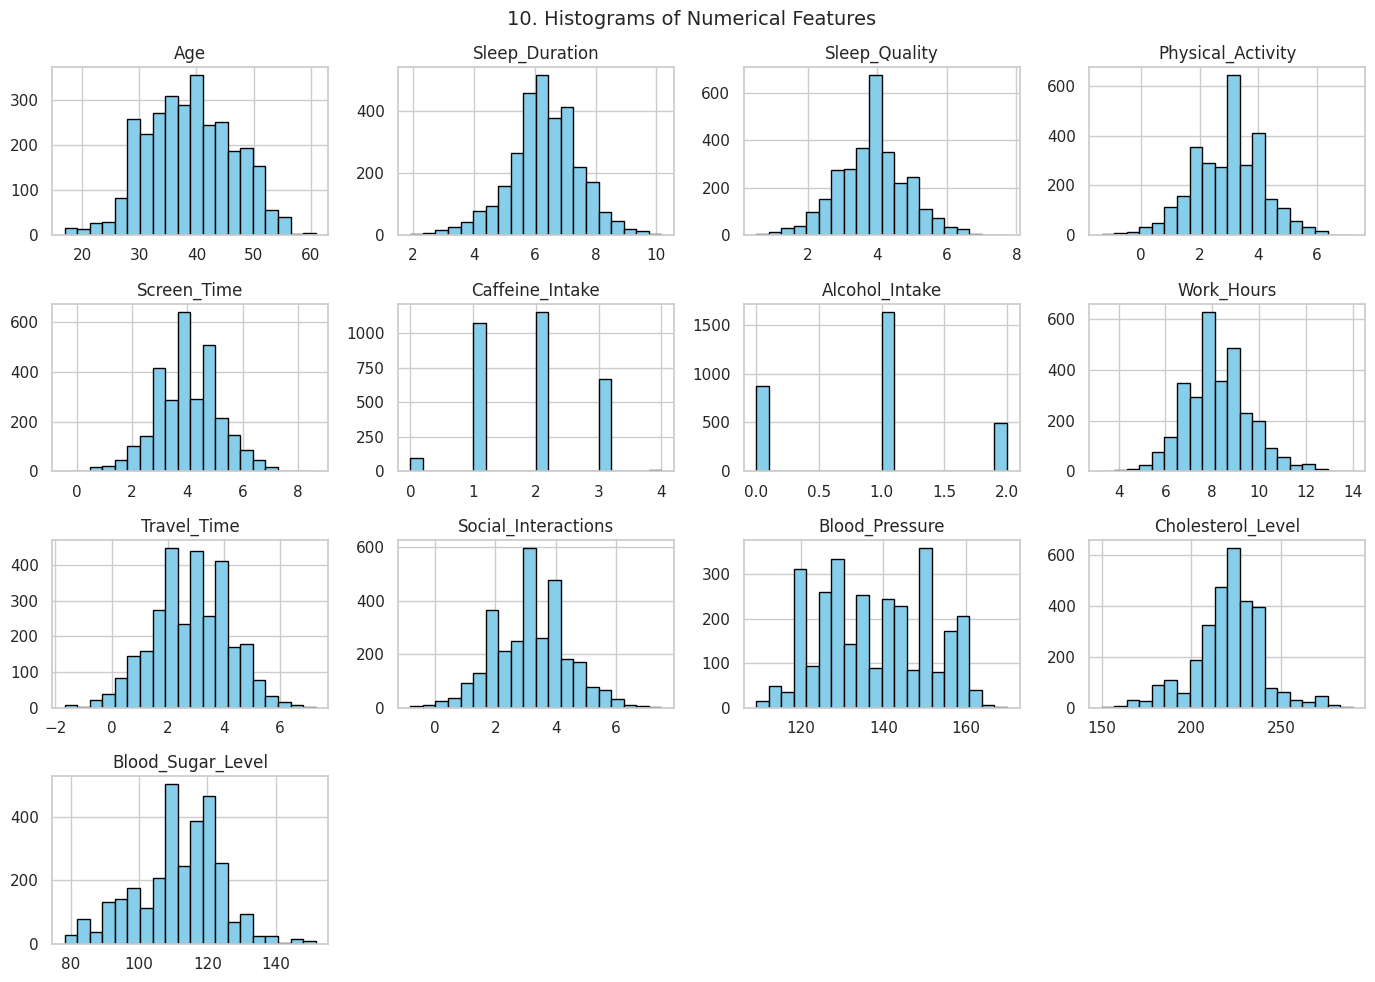

In [ ]:
# 10.
plt.figure(figsize=(14, 10))
df[num_cols].hist(bins=20, figsize=(14, 10), layout=(4, 4), color='skyblue', edgecolor='black')
plt.suptitle('10. Histograms of Numerical Features', fontsize=14)
plt.tight_layout()
plt.show()

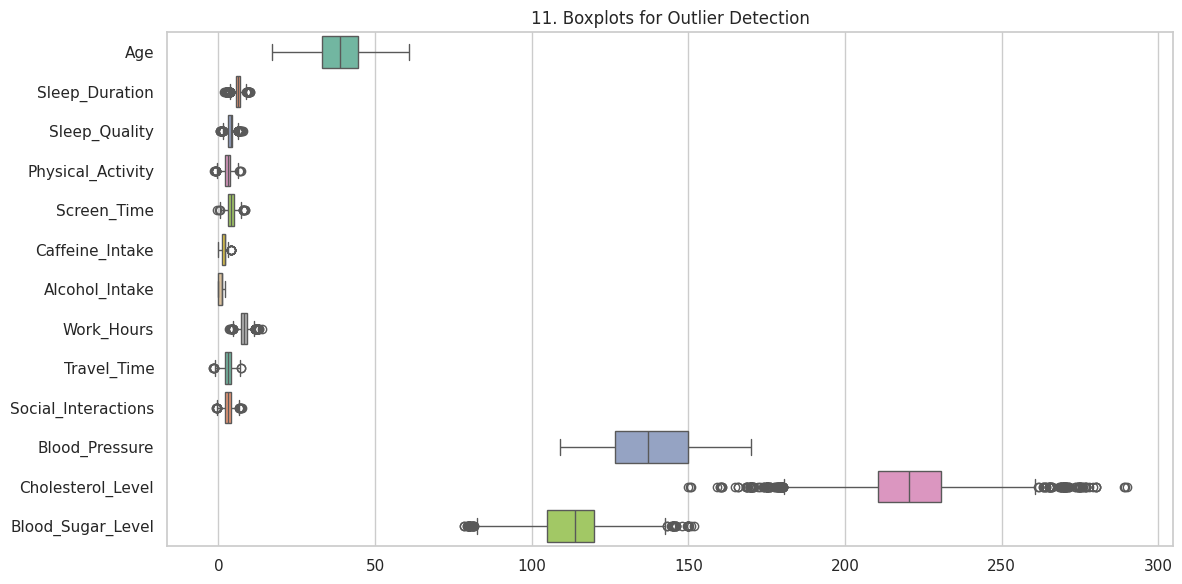

In [ ]:
# 11.
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[num_cols], orient='h', palette='Set2')
plt.title('11. Boxplots for Outlier Detection')
plt.tight_layout()
plt.show()

/tmp/ipykernel_485/546279843.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=ax, palette='Set3')
/tmp/ipykernel_485/546279843.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=ax, palette='Set3')
/tmp/ipykernel_485/546279843.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, ax=ax, palette='Set3')
/tmp/ipykernel_485/546279843.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set 

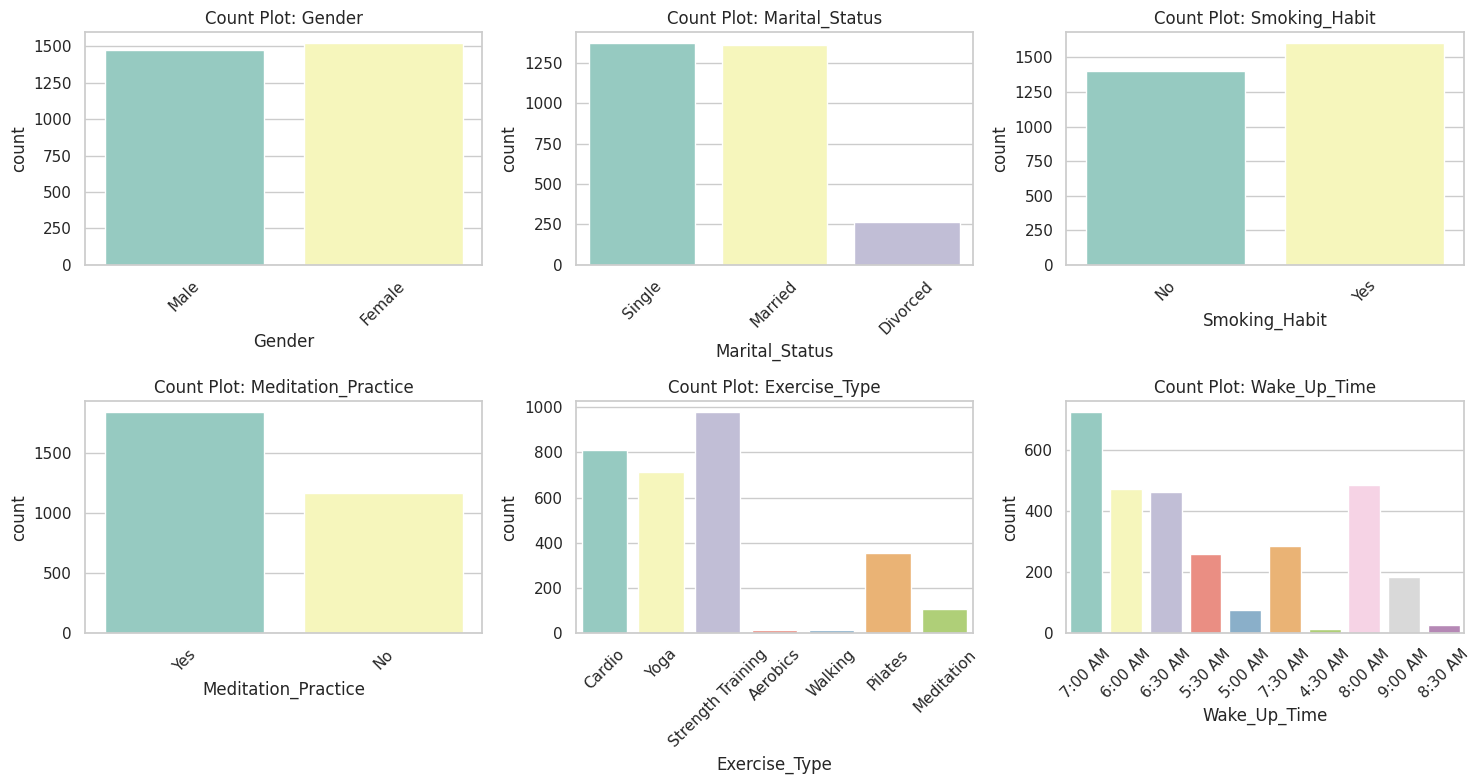

In [ ]:
# 12.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols_plot = ['Gender', 'Marital_Status', 'Smoking_Habit', 'Meditation_Practice', 'Exercise_Type', 'Wake_Up_Time']
for ax, col in zip(axes.flatten(), cols_plot):
    sns.countplot(data=df, x=col, ax=ax, palette='Set3')
    ax.set_title(f'Count Plot: {col}')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

/tmp/ipykernel_485/3893879047.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y='Sleep_Duration', data=df, palette='Blues')


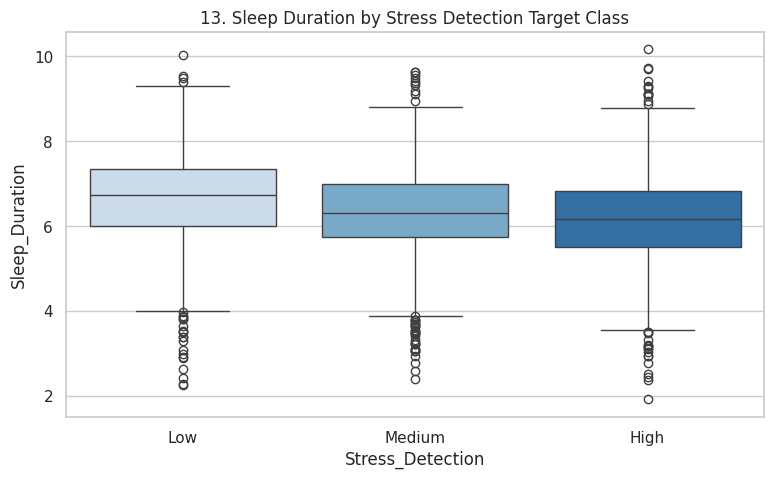

In [ ]:
# 13.
plt.figure(figsize=(9, 5))
sns.boxplot(x=target_col, y='Sleep_Duration', data=df, palette='Blues')
plt.title('13. Sleep Duration by Stress Detection Target Class')
plt.show()

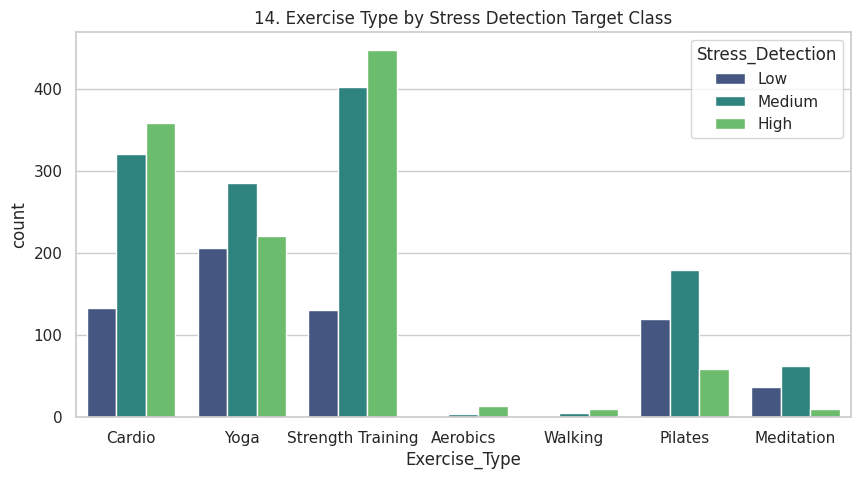

In [ ]:
# 14.
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Exercise_Type', hue=target_col, palette='viridis')
plt.title('14. Exercise Type by Stress Detection Target Class')
plt.show()

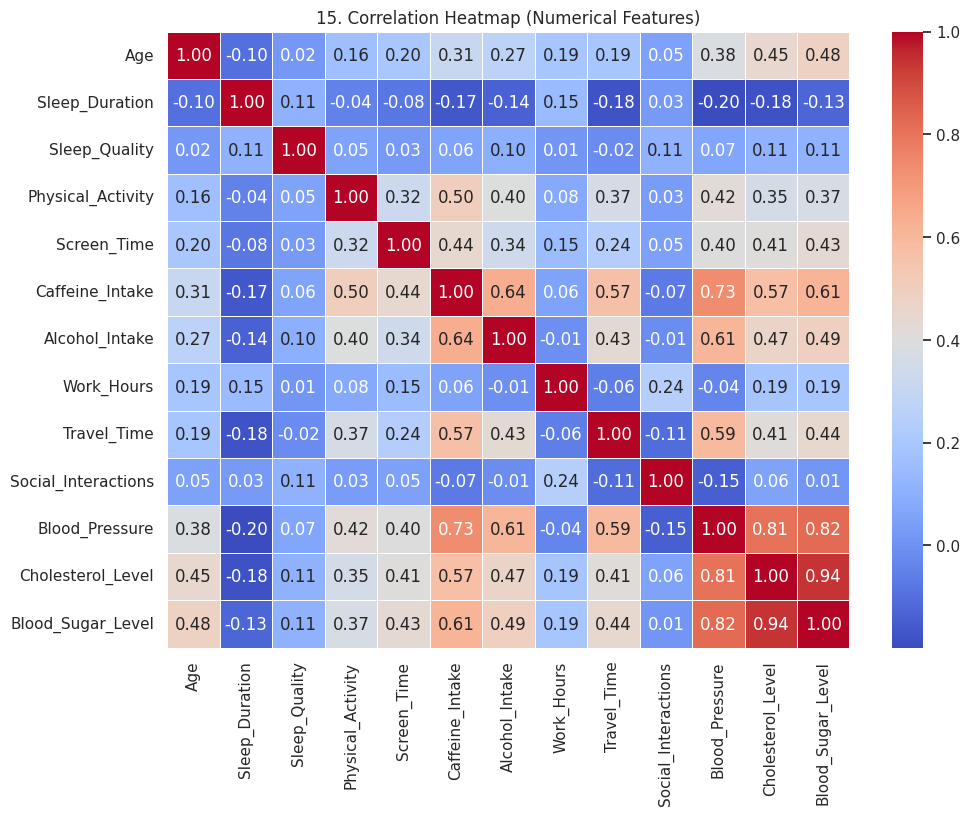

In [ ]:
# 15.
plt.figure(figsize=(11, 8))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('15. Correlation Heatmap (Numerical Features)')
plt.show()

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

In [ ]:
#16.
X_num = df[num_cols].dropna()
vif_df = pd.DataFrame({
    "Feature": X_num.columns,
    "VIF": [variance_inflation_factor(X_num.values, i) for i in range(X_num.shape[1])]
})
print("--- 16. Variance Inflation Factor (VIF) ---")
print(vif_df.sort_values(by="VIF", ascending=False))

--- 16. Variance Inflation Factor (VIF) ---
                Feature        VIF
12    Blood_Sugar_Level  10.662677
11    Cholesterol_Level   9.854911
10       Blood_Pressure   6.099163
5       Caffeine_Intake   2.924118
6        Alcohol_Intake   1.874463
8           Travel_Time   1.706374
3     Physical_Activity   1.407995
4           Screen_Time   1.353188
0                   Age   1.339934
7            Work_Hours   1.305120
9   Social_Interactions   1.181107
1        Sleep_Duration   1.138547
2         Sleep_Quality   1.055746


In [ ]:
# 17.
X_encoded = df.drop(columns=[target_col]).apply(lambda col: LabelEncoder().fit_transform(col.astype(str)))
y_encoded = LabelEncoder().fit_transform(df[target_col])

mi_scores = mutual_info_classif(X_encoded, y_encoded, random_state=42)
mi_df = pd.DataFrame({'Feature': X_encoded.columns, 'MI_Score': mi_scores}).sort_values('MI_Score', ascending=False)
print("\n--- 17. Mutual Information Feature Ranking ---")
print(mi_df)


--- 17. Mutual Information Feature Ranking ---
                Feature  MI_Score
2            Occupation  0.259578
19    Cholesterol_Level  0.196374
20    Blood_Sugar_Level  0.173815
10      Caffeine_Intake  0.164512
18       Blood_Pressure  0.156745
11       Alcohol_Intake  0.122200
8     Physical_Activity  0.071647
14          Travel_Time  0.069098
9           Screen_Time  0.067743
0                   Age  0.062641
7              Bed_Time  0.059091
6          Wake_Up_Time  0.051323
16  Meditation_Practice  0.051159
17        Exercise_Type  0.045273
13           Work_Hours  0.035875
3        Marital_Status  0.032945
12        Smoking_Habit  0.032105
5         Sleep_Quality  0.027374
4        Sleep_Duration  0.025437
1                Gender  0.019924
15  Social_Interactions  0.019663


In [ ]:
# 18.
df['Work_to_Sleep_Ratio'] = df['Work_Hours'] / (df['Sleep_Duration'] + 1e-5)
print("\n--- 18. Feature Interaction Analysis (Work_to_Sleep_Ratio) ---")
print(df.groupby(target_col)['Work_to_Sleep_Ratio'].mean())


--- 18. Feature Interaction Analysis (Work_to_Sleep_Ratio) ---
Stress_Detection
High      1.453155
Low       1.253436
Medium    1.304656
Name: Work_to_Sleep_Ratio, dtype: float64


In [ ]:
from scipy import stats
from statsmodels.stats.multitest import multipletests

In [ ]:
# 19.
low_s = df[df[target_col] == 'Low']['Sleep_Duration']
med_s = df[df[target_col] == 'Medium']['Sleep_Duration']
high_s = df[df[target_col] == 'High']['Sleep_Duration']

f_stat, p1 = stats.f_oneway(low_s, med_s, high_s)
chi2_g, p2, _, _ = stats.chi2_contingency(pd.crosstab(df['Gender'], df[target_col]))
chi2_m, p3, _, _ = stats.chi2_contingency(pd.crosstab(df['Meditation_Practice'], df[target_col]))
t_stat, p4 = stats.ttest_ind(low_s, high_s)

p_values = [p1, p2, p3, p4]
test_names = [
    "ANOVA: Sleep Duration across Stress Levels",
    "Chi-Square: Gender vs Stress Level",
    "Chi-Square: Meditation Practice vs Stress Level",
    "t-test: Sleep Duration (Low vs High Stress)"
]

In [ ]:
# 20.
d_eff = (low_s.mean() - high_s.mean()) / np.sqrt((low_s.std()**2 + high_s.std()**2) / 2)
print(f"--- 20. Cohen's d Effect Size (Low vs High Stress Sleep Duration) ---: {d_eff:.4f}")



--- 20. Cohen's d Effect Size (Low vs High Stress Sleep Duration) ---: 0.3890


In [ ]:
# 21.
reject_bonf, p_corrected_bonf, _, _ = multipletests(p_values, alpha=0.05, method='bonferroni')
results_ht = pd.DataFrame({
    'Test': test_names,
    'Raw_p': p_values,
    'Bonferroni_Corrected_p': p_corrected_bonf,
    'Reject_H0': reject_bonf
})
print("\n--- 21. Multiple-Testing Correction Results ---")
print(results_ht)


--- 21. Multiple-Testing Correction Results ---
                                              Test         Raw_p  \
0       ANOVA: Sleep Duration across Stress Levels  2.066141e-14   
1               Chi-Square: Gender vs Stress Level  4.335890e-14   
2  Chi-Square: Meditation Practice vs Stress Level  3.624950e-63   
3      t-test: Sleep Duration (Low vs High Stress)  5.669532e-15   

   Bonferroni_Corrected_p  Reject_H0  
0            8.264562e-14       True  
1            1.734356e-13       True  
2            1.449980e-62       True  
3            2.267813e-14       True  


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
X_scaled = StandardScaler().fit_transform(X_encoded)

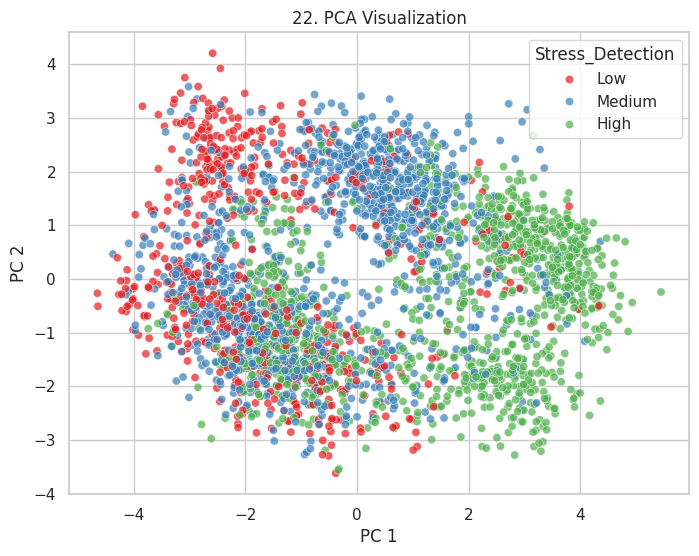

In [ ]:
# 22.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df[target_col], palette='Set1', alpha=0.7)
plt.title('22. PCA Visualization')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.show()

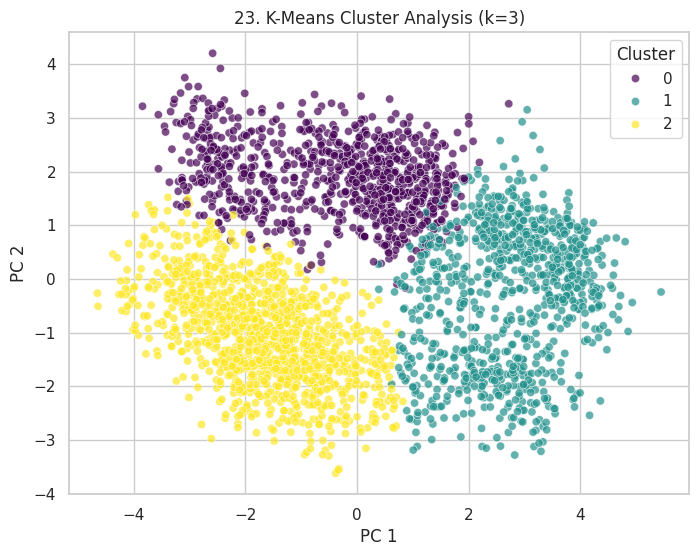

In [ ]:
# 23.
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['Cluster'], palette='viridis', alpha=0.7)
plt.title('23. K-Means Cluster Analysis (k=3)')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.show()



In [ ]:
# 24.
print("\n--- 24. Comparison of Clusters with Actual Target Labels ---")
print(pd.crosstab(df['Cluster'], df[target_col]))


--- 24. Comparison of Clusters with Actual Target Labels ---
Stress_Detection  High  Low  Medium
Cluster                            
0                   76  230     542
1                  710   46     146
2                  332  348     570


In [ ]:
# Nominal
nominal_cols = ['Occupation', 'Marital_Status', 'Exercise_Type']
df = pd.get_dummies(df, columns=nominal_cols, drop_first=True, dtype=int)
print(df.head())

    Age  Gender  Sleep_Duration  Sleep_Quality Wake_Up_Time  Bed_Time  \
0  30.0    Male             7.0            4.0      7:00 AM  10:00 PM   
1  35.0  Female             6.0            3.0      6:00 AM  11:00 PM   
2  40.0    Male             7.0            4.0      7:00 AM  10:00 PM   
3  35.0    Male             7.0            4.0      7:00 AM  10:00 PM   
4  29.0  Female             8.0            5.0      6:30 AM  10:30 PM   

   Physical_Activity  Screen_Time  Caffeine_Intake  Alcohol_Intake  ...  \
0                2.0          4.0                1               0  ...   
1                1.0          3.0                0               1  ...   
2                2.0          4.0                1               0  ...   
3                2.0          4.0                1               0  ...   
4                3.0          2.0                1               0  ...   

  Occupation_Web Developer  Occupation_Writer  Marital_Status_Married  \
0                        0           

In [ ]:
# Binary
binary_map = {
    'Female': 0, 'Male': 1,
    'No': 0, 'Yes': 1
}

binary_cols = ['Gender', 'Smoking_Habit', 'Meditation_Practice']

for col in binary_cols:
    df[col] = df[col].map(binary_map)
print(df[binary_cols].head())

   Gender  Smoking_Habit  Meditation_Practice
0       1              0                    1
1       0              0                    0
2       1              0                    1
3       1              0                    1
4       0              0                    1


In [ ]:
df['Wake_Up_Hour'] = pd.to_datetime(df['Wake_Up_Time'], format='%I:%M %p').dt.hour + \
                     pd.to_datetime(df['Wake_Up_Time'], format='%I:%M %p').dt.minute / 60.0

df['Bed_Hour'] = pd.to_datetime(df['Bed_Time'], format='%I:%M %p').dt.hour + \
                 pd.to_datetime(df['Bed_Time'], format='%I:%M %p').dt.minute / 60.0

df['Calculated_Sleep_Hours'] = df.apply(
    lambda row: (row['Wake_Up_Hour'] - row['Bed_Hour'])
    if row['Wake_Up_Hour'] > row['Bed_Hour']
    else (24.0 - row['Bed_Hour'] + row['Wake_Up_Hour']),
    axis=1
)
df = df.drop(columns=['Wake_Up_Time', 'Bed_Time'])
print(df[['Wake_Up_Hour', 'Bed_Hour', 'Calculated_Sleep_Hours']].head())

   Wake_Up_Hour  Bed_Hour  Calculated_Sleep_Hours
0           7.0      22.0                     9.0
1           6.0      23.0                     7.0
2           7.0      22.0                     9.0
3           7.0      22.0                     9.0
4           6.5      22.5                     8.0


In [ ]:

print(" Class Distribution ")
print(df['Stress_Detection'].value_counts())

print("\n Class Distribution ")
print(df['Stress_Detection'].value_counts(normalize=True) * 100)

 Class Distribution 
Stress_Detection
1    1258
2    1118
0     624
Name: count, dtype: int64

 Class Distribution 
Stress_Detection
1    41.933333
2    37.266667
0    20.800000
Name: proportion, dtype: float64


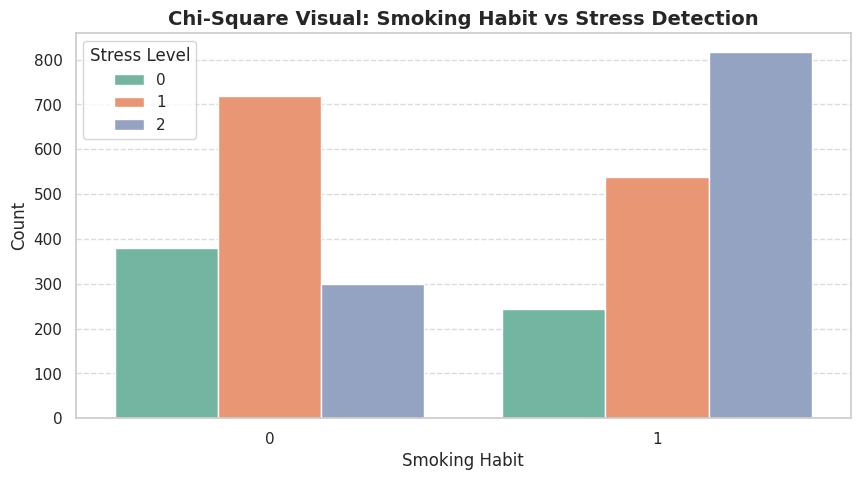

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='Smoking_Habit',
    hue='Stress_Detection',
    palette='Set2',
)

plt.title(
    "Chi-Square Visual: Smoking Habit vs Stress Detection",
    fontsize=14,
    fontweight='bold',
)
plt.xlabel("Smoking Habit", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.legend(title="Stress Level")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

/tmp/ipykernel_485/1269846433.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


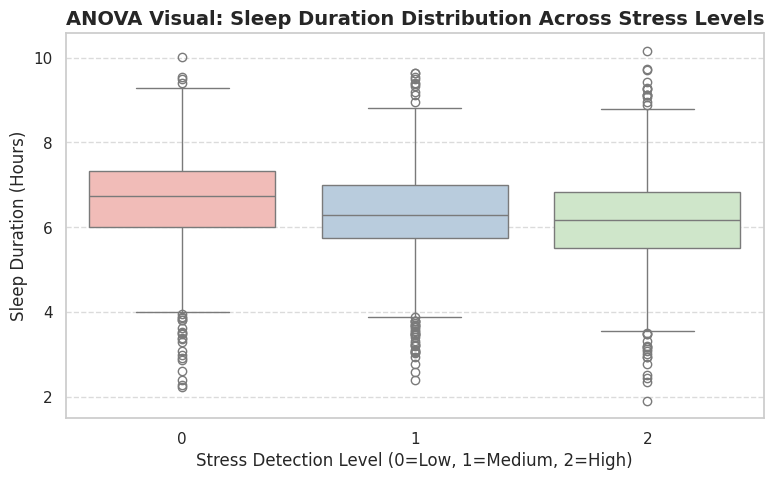

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Stress_Detection",
    y="Sleep_Duration",
    palette="Pastel1",
    order=[0, 1, 2],
)

plt.title(
    "ANOVA Visual: Sleep Duration Distribution Across Stress Levels",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Stress Detection Level (0=Low, 1=Medium, 2=High)", fontsize=12)
plt.ylabel("Sleep Duration (Hours)", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

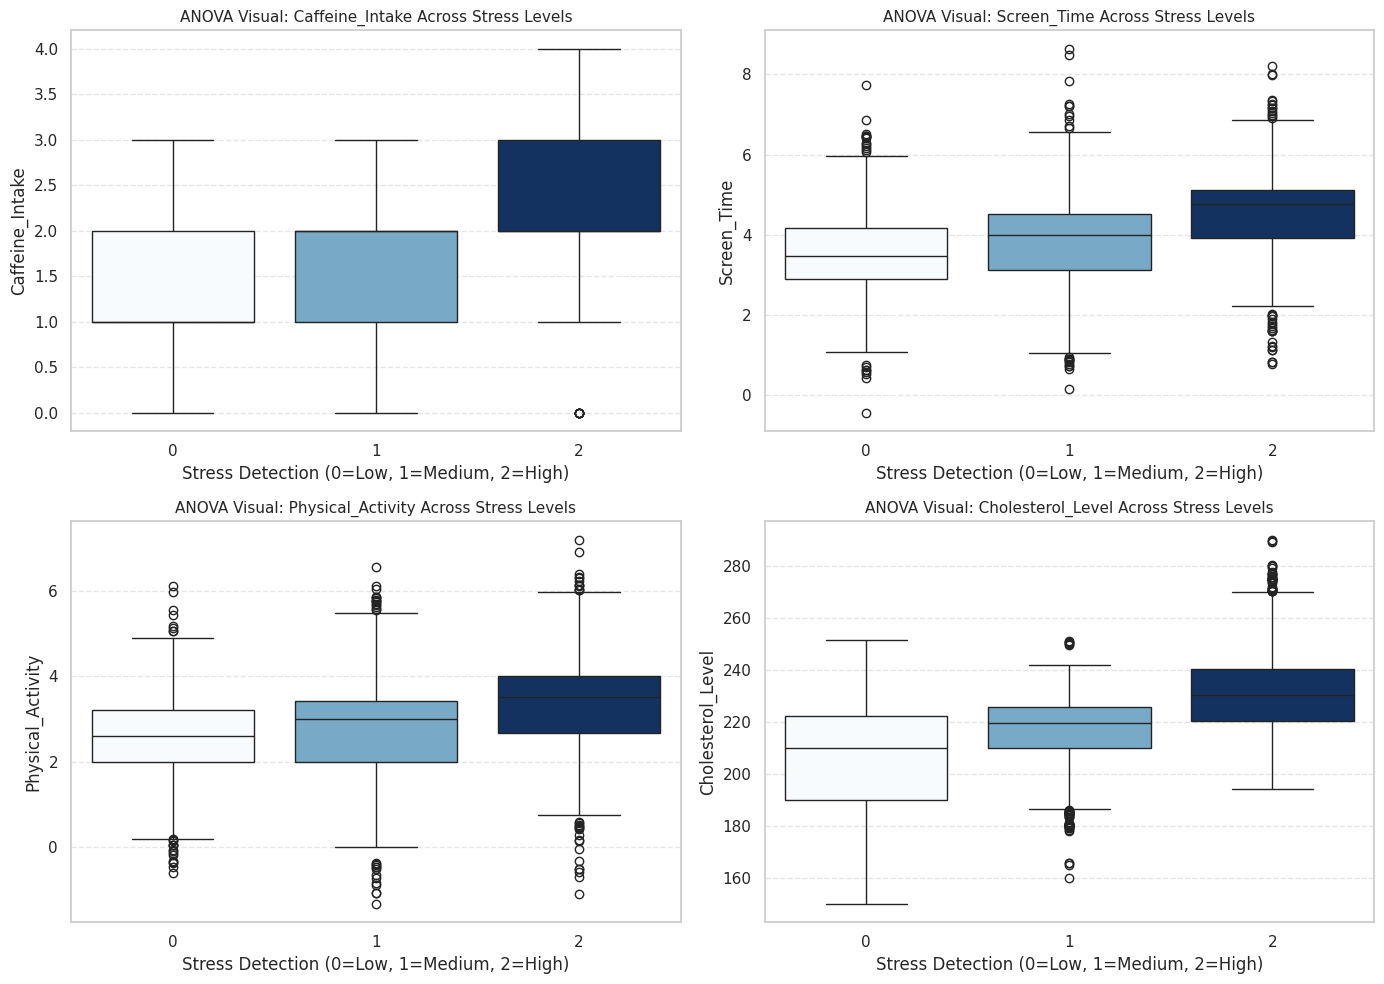

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Updated numerical feature list ('Heart_Rate' is replaced with 'Caffeine_Intake')
features = [
    'Caffeine_Intake',
    'Screen_Time',
    'Physical_Activity',
    'Cholesterol_Level',
]

# 2x2 Grid Subplot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(
        ax=axes[i],
        data=df,
        x='Stress_Detection',
        y=col,
        hue='Stress_Detection',
        palette='Blues',
        order=[0, 1, 2],
        legend=False,
    )
    axes[i].set_title(f'ANOVA Visual: {col} Across Stress Levels', fontsize=11)
    axes[i].set_xlabel("Stress Detection (0=Low, 1=Medium, 2=High)")
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()